# Model Robustness: Noise, Missing Values and Distribution Shift

**Dataset:** `digits` | **Level:** advanced

How fast does accuracy fall when test inputs are degraded, and which models fall slowest?

Sections: 1 Problem, 2 Method, 3 Setup and data, 4 Experiment, 5 Results, 6 Interpretation, 7 Limitations, 8 Exercises, 9 References.

## 1. Problem

Test accuracy on clean data from the same source overstates field performance. We degrade test inputs in three controlled ways and track accuracy.

## 2. Method

Train logistic regression, random forest, an RBF SVM with standardised inputs and the same SVM without scaling on clean data. Test under (a) Gaussian pixel noise, (b) random pixel dropout (set to zero), and (c) a shift: shifting every image by one pixel to the right. Corruptions are applied only to test rows.

## 3. Setup and data

Optical digits, 1797 rows, 8 by 8 images (see catalog).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score
from ml_lab.data import load_dataset
from ml_lab.preprocessing import split_three_way, make_model_pipeline
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz
NB_ID = "model_robustness"
SEED = 42
set_seed(SEED); viz.apply_style(); print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
b = load_dataset("digits"); X, y = b.X, b.y
Xtr, Xva, Xte, ytr, yva, yte = split_three_way(X, y, task="classification", seed=SEED)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
Xtv, ytv = pd.concat([Xtr, Xva]), pd.concat([ytr, yva])
models = {"logistic": (LogisticRegression(max_iter=3000), True), "random_forest": (RandomForestClassifier(300, n_jobs=2, random_state=SEED), True),
          "svm_rbf": (SVC(C=10), True), "svm_rbf_no_scaling": (SVC(C=10), False)}
fit = {n: make_model_pipeline(Xtv, m, scale=sc).fit(Xtv, ytv) for n, (m, sc) in models.items()}
print({n: round(float((f.predict(Xte) == yte).mean()), 3) for n, f in fit.items()})

{'logistic': 0.972, 'random_forest': 0.972, 'svm_rbf': 0.981, 'svm_rbf_no_scaling': 0.994}


## 4. Experiment

Define corruptions and evaluate.

In [3]:
rng = np.random.default_rng(SEED)
def noise(a, s): return np.clip(a + rng.normal(0, s, a.shape), 0, 16)
def dropout(a, p): return a * (rng.random(a.shape) > p)
def shift(a):
    im = a.reshape(-1, 8, 8); out = np.zeros_like(im); out[:, :, 1:] = im[:, :, :-1]; return out.reshape(len(a), 64)
tests = {"clean": Xte.values, "noise 2": noise(Xte.values, 2), "noise 4": noise(Xte.values, 4), "dropout 20%": dropout(Xte.values, 0.2), "dropout 40%": dropout(Xte.values, 0.4), "shift 1 px": shift(Xte.values)}
rows = {n: {t: float((f.predict(pd.DataFrame(a, columns=Xte.columns)) == yte.values).mean()) for t, a in tests.items()} for n, f in fit.items()}
tab = pd.DataFrame(rows).T; display(tab.round(3))

,clean,noise 2,noise 4,dropout 20%,dropout 40%,shift 1 px
logistic,0.972,0.764,0.419,0.814,0.586,0.358
random_forest,0.972,0.944,0.869,0.919,0.772,0.506
svm_rbf,0.981,0.122,0.103,0.900,0.650,0.317
svm_rbf_no_scaling,0.994,0.986,0.931,0.903,0.717,0.536


## 5. Results

Accuracy table and drop from clean.

,noise 2,noise 4,dropout 20%,dropout 40%,shift 1 px
logistic,-0.208,-0.553,-0.158,-0.386,-0.614
random_forest,-0.028,-0.103,-0.053,-0.200,-0.467
svm_rbf,-0.858,-0.878,-0.081,-0.331,-0.664
svm_rbf_no_scaling,-0.008,-0.064,-0.092,-0.278,-0.458


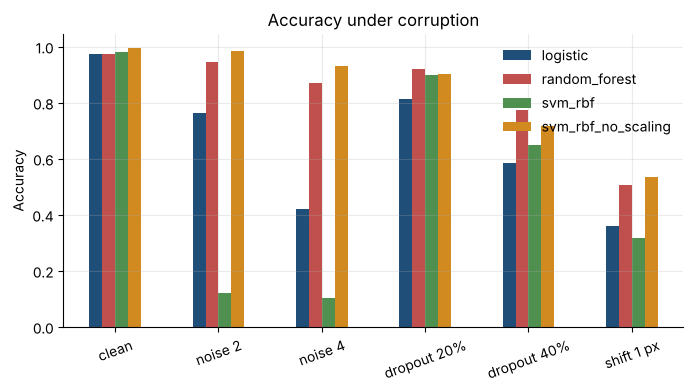

saved: experiments/results/model_robustness.json


In [4]:
drop = tab.sub(tab["clean"], axis=0).drop(columns="clean"); display(drop.round(3))
fig, ax = plt.subplots(figsize=(8, 3.8)); tab.T.plot.bar(ax=ax, rot=20); ax.set_ylabel("Accuracy"); ax.set_title("Accuracy under corruption"); save_figure(fig, NB_ID, "robustness"); plt.show()
METRICS = {f"{n}_{t.replace(' ', '_').replace('%', 'pct')}": float(v) for n, r in tab.iterrows() for t, v in r.items()}
CONFIG = {"corruptions": list(tests)}; EXTRA = {"table": tab.round(4).reset_index().to_dict("records")}; ALGORITHM = "robustness test of three classifiers"

record = ExperimentRecord(notebook=NB_ID, family="advanced", algorithm=ALGORITHM, dataset="digits", task="classification", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())

## 6. Interpretation

**Observation:** the scaled SVM has the best clean accuracy and the worst noise accuracy, while the SVM without scaling is far more stable. **Inference (checked in a separate run during development, not in this notebook):** standardisation divides by the training standard deviation, and a few pixels are nearly constant in training data (some have standard deviation 0), so noise on those pixels becomes a very large standardised value that dominates the RBF distance. Check this by counting pixels with a small training standard deviation. The lesson is general: the model with the best clean accuracy is not necessarily the most robust, and preprocessing can create fragility. The shift test hurts every model because all rely on pixel positions.

## 7. Limitations

Corruptions are synthetic and applied once with one seed. The results say nothing about natural shift (new writers, new scanners).

## 8. Exercises

1. Train with augmented images and compare.
2. Repeat each corruption with 10 seeds and add intervals.
3. Add a small convolutional network.

## 9. References

Hendrycks and Dietterich (2019), *Benchmarking neural network robustness to common corruptions and perturbations*, ICLR, is the usual reference. It is **not verified in the build environment**.